In [1]:
import math
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# 1. USER INPUT
x0 = float(input("Enter initial solution x0: "))
T0 = float(input("Enter initial temperature T0: "))
alpha = float(input("Enter cooling rate alpha (0 < alpha < 1): "))
T_min = float(input("Enter minimum temperature T_min: "))

if T0 <= 0 or T_min <= 0 or not (0 < alpha < 1):
    raise ValueError("Use T0 > 0, T_min > 0 and 0 < alpha < 1.")

print("\nParameters entered:")
print(f"x0 = {x0}, T0 = {T0}, alpha = {alpha}, T_min = {T_min}")


Parameters entered:
x0 = 5.0, T0 = 100.0, alpha = 0.9, T_min = 0.1


In [3]:
# 2. FIXED SETTINGS
neighbour_step = 1
iterations_per_temperature = 1
seed = 42

random.seed(seed)
np.random.seed(seed)

# Objective function
def f(x):
    return x**2 + 10 * math.sin(x)


In [4]:
# 3. SIMULATED ANNEALING
current_x = x0
current_value = f(current_x)

best_x = current_x
best_value = current_value

temperature = T0
history = []
iteration = 0

# Record initial state
history.append({
    "Iteration": 0,
    "Temperature": temperature,
    "Current x": current_x,
    "Current f(x)": current_value,
    "Candidate x": np.nan,
    "Candidate f(x)": np.nan,
    "Delta": np.nan,
    "Acceptance Probability": np.nan,
    "Accepted": True
})

while temperature >= T_min:

    for _ in range(iterations_per_temperature):
        iteration += 1

        # Generate neighbouring solution
        candidate_x = current_x + random.choice(
            [-neighbour_step, neighbour_step]
        )

        candidate_value = f(candidate_x)
        delta = candidate_value - current_value

        # Acceptance decision
        if delta <= 0:
            probability = 1.0
            accepted = True
        else:
            probability = math.exp(-delta / temperature)
            accepted = random.random() < probability

        # Update current solution
        if accepted:
            current_x = candidate_x
            current_value = candidate_value

        # Keep track of the best solution found
        if current_value < best_value:
            best_x = current_x
            best_value = current_value

        # Record the state after the decision
        history.append({
            "Iteration": iteration,
            "Temperature": temperature,
            "Current x": current_x,
            "Current f(x)": current_value,
            "Candidate x": candidate_x,
            "Candidate f(x)": candidate_value,
            "Delta": delta,
            "Acceptance Probability": probability,
            "Accepted": accepted
        })

    # Cool the system
    temperature *= alpha

In [5]:
# 4. DISPLAY ITERATION TABLE
results = pd.DataFrame(history)

print("\nTotal iterations:", iteration)
display(results)

# 5. FINAL RESULT
print("\nSimulated Annealing Result")
print("--------------------------")
print(f"Best x found = {best_x:.6f}")
print(f"Minimum f(x) = {best_value:.6f}")
print(f"Final current x = {current_x:.6f}")
print(f"Final current f(x) = {current_value:.6f}")


Total iterations: 66


,Iteration,Temperature,Current x,Current f(x),Candidate x,Candidate f(x),Delta,Acceptance Probability,Accepted
0,0,100.000000,5.0,15.410757,NaN,NaN,NaN,NaN,True
1,1,100.000000,4.0,8.431975,4.0,8.431975,-6.978782,1.000000e+00,True
2,2,90.000000,3.0,10.411200,3.0,10.411200,1.979225,9.782487e-01,True
3,3,81.000000,2.0,13.092974,2.0,13.092974,2.681774,9.674338e-01,True
4,4,72.900000,1.0,9.414710,1.0,9.414710,-3.678264,1.000000e+00,True
...,...,...,...,...,...,...,...,...,...
62,62,0.161731,4.0,8.431975,5.0,15.410757,6.978782,1.819467e-19,False
63,63,0.145558,4.0,8.431975,5.0,15.410757,6.978782,1.505621e-21,False
64,64,0.131002,4.0,8.431975,5.0,15.410757,6.978782,7.313556e-24,False
65,65,0.117902,4.0,8.431975,3.0,10.411200,1.979225,5.122402e-08,False



Simulated Annealing Result
--------------------------
Best x found = -1.000000
Minimum f(x) = -7.414710
Final current x = 4.000000
Final current f(x) = 8.431975


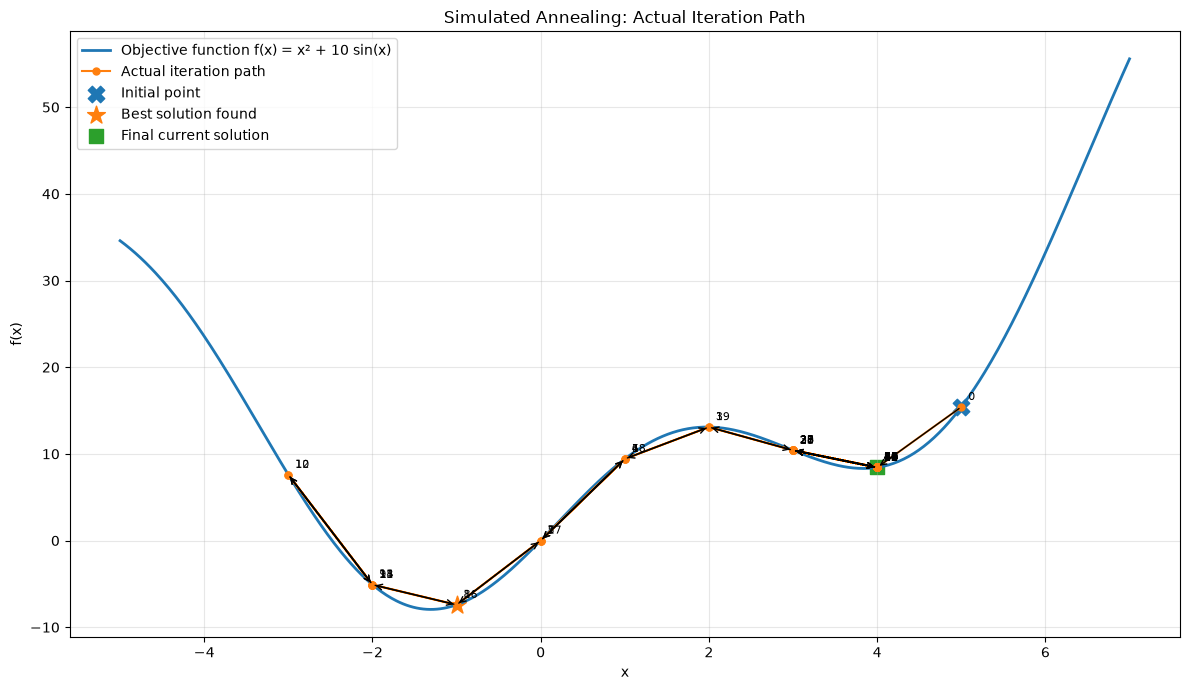

In [6]:
# 6. PLOT THE OBJECTIVE FUNCTION AND ITERATION PATH
path_x = results["Current x"].to_numpy()
path_y = results["Current f(x)"].to_numpy()

xmin = min(path_x.min(), best_x) - 2
xmax = max(path_x.max(), best_x) + 2

x_values = np.linspace(xmin, xmax, 600)
y_values = x_values**2 + 10 * np.sin(x_values)

plt.figure(figsize=(12, 7))

plt.plot(
    x_values, y_values,
    linewidth=2,
    label="Objective function f(x) = x² + 10 sin(x)"
)

plt.plot(
    path_x, path_y,
    marker="o",
    markersize=5,
    linewidth=1.5,
    label="Actual iteration path"
)

# Direction arrows
for i in range(len(results) - 1):
    x1, y1 = path_x[i], path_y[i]
    x2, y2 = path_x[i + 1], path_y[i + 1]

    if x1 != x2 or y1 != y2:
        plt.annotate(
            "",
            xy=(x2, y2),
            xytext=(x1, y1),
            arrowprops=dict(arrowstyle="->", linewidth=1)
        )

# Initial, best and final points
plt.scatter(
    x0, f(x0), s=140, marker="X",
    label="Initial point"
)

plt.scatter(
    best_x, best_value, s=180, marker="*",
    label="Best solution found"
)

plt.scatter(
    current_x, current_value, s=100, marker="s",
    label="Final current solution"
)

# Iteration labels
for _, row in results.iterrows():
    plt.annotate(
        str(int(row["Iteration"])),
        (row["Current x"], row["Current f(x)"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Simulated Annealing: Actual Iteration Path")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()
